# Building the samples

This notebook is the **only** place where the stellar samples are defined. It applies every cut to the SDSS-V Astra ASPCAP catalog and writes each sample to a file. The analysis code in `src/midplane/` and the other notebooks only read these files and do not need to know how the stars were chosen.

**Input**
- `astraAllStarASPCAP-0.8.0.fits.gz`: SDSS-V Astra ASPCAP catalog

**Outputs** (in `data/`)
- `final_sample_zsun0.fits`: the main sample. It has every catalog column plus computed columns (distance, Galactocentric x, y, z, R, phi, [Mg/Fe] and its uncertainty, [Al/Fe], [Mg/Mn], and the S/N we used). The cut values are written to the FITS header.
- `final_sample_zsun0_zgrbits45.fits`: a variant with a looser ZGR quality cut (section 6)
- `final_sample_zsun0_norc.fits`: a variant with the red clump removed

The first code cell (after imports) contains the numbers that define the sample selection. The next cell turns those numbers into one boolean mask per cut (`selection_masks`). Each mask is computed on the whole parent catalog, and a sample is just the stars that pass all of them. To make a variant, change or add one mask and save the result. Section 6 shows how.

In [1]:
from pathlib import Path

import astropy.coordinates as coord
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.coordinates import Distance, SkyCoord
from astropy.table import Table
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
from matplotlib.path import Path as PolyPath

from midplane.cells import (
    EXAMPLE_CELLS,
    N_R,
    N_SEG,
    PHI_EDGES,
    R_EDGES,
    cell_outline,
    outline,
)
from midplane.utils import col_to_float_array

In [2]:
# --- input and output files -----------------------------------------------
REPO_ROOT = Path.cwd().parent  # this notebook lives in <repo>/notebooks/
DATA_DIR = REPO_ROOT / "data"  # CHANGE to the folder holding the catalog
ASTRA_FILE = DATA_DIR / "astraAllStarASPCAP-0.8.0.fits.gz"
OUT_SAMPLE = DATA_DIR / "final_sample_zsun0.fits"
FIG_DIR = REPO_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

In [3]:
# =============================================================================
# Numbers that define the sample
# =============================================================================
# cut 1: red giant branch polygon in (Teff [K], logg), plus Teff and logg ranges
GB_VERTICES = np.array(
    [
        [5250, 1.85],
        [4700, 1.85],
        [4300, 1.25],
        [3900, 0.70],
        [3650, 0.5],
        [3650, 1.6],
        [4000, 2.00],
        [4400, 2.75],
        [4600, 3.5],
        [5250, 3.5],
    ]
)
TEFF_RANGE = (3600, 7500)
LOGG_RANGE = (-1, 6)  # exclusive

SNR_MIN = 10  # cut 2: keep S/N > SNR_MIN
ZGR_QUALITY_MAX = 8  # cut 7: keep zgr_quality_flags < ZGR_QUALITY_MAX

# cut 8: low-alpha disk, polygon in ([Fe/H], [Mg/Fe]). The top edge is the
# low/high-alpha dividing line, which bends at [Fe/H] = -0.1; the left edge is
# the [Fe/H] floor. The bottom and right edges lie outside the data.
FEH_MIN = -0.8
LOW_ALPHA_VERTICES = np.array(
    [
        [0.55, 0.075],
        [-0.1, 0.075],
        [-0.5, 0.18],
        [FEH_MIN, 0.18],
        [FEH_MIN, 0.0],
        [0, -0.2],
        [0.55, -0.2],
    ]
)

# cut 9: polygon in ([Al/Fe], [Mg/Mn])
ALFE_MGMN_VERTICES = np.array(
    [
        [-0.4, -0.25],  # lower-left
        [0.15, -0.40],  # lower-right
        [0.6, 0.7],  # upper-right
        [-0.2, 0.70],  # upper-left
    ]
)

# Galactocentric frame for the computed positions: Sun 8.275 kpc from the
# centre and exactly on the midplane (z_sun = 0)
GALCEN_DISTANCE_KPC = 8.275
GALCEN_FRAME = coord.Galactocentric(
    galcen_distance=GALCEN_DISTANCE_KPC * u.kpc,
    galcen_v_sun=[8, 254, 8]
    * u.km
    / u.s,  # only defines the frame; no velocities are used
    z_sun=0 * u.pc,
)

# --- figure style ---------------------------------------------------------
RED = "red"
CMAP = "Greys"  # white = empty, black = densest

## The cuts

Each row is one boolean mask in `selection_masks` below. Every mask is computed on the parent catalog, and the sample is the stars that pass all of them. Stars with a non-finite value of any quantity a cut uses fail that cut, so no separate finiteness cuts are needed. The cut log counts the stars left after each cut in this order. We do not cut on radial velocity, proper motion or Galactocentric radius.

| # | Cut | What it does |
|---|-----|--------------|
| 1 | Giant branch | (Teff, logg) must lie inside the red giant branch polygon, with Teff 3000 to 7500 K and logg between -2 and 6.5. |
| 2 | S/N | Spectral S/N > 20, from the Astra `snr` column. A value of 0 means no measurement and is treated as missing. |
| 3 | `flag_bad` | The ASPCAP `flag_bad` flag must not be set. In Astra it is built from the ASPCAP `result_flags` and is set if the fit shows any sign of failure or unreliability (suspicious or unphysical parameters, high reduced chi-squared, high v sin i or microturbulence, a parameter at the model grid edge, a failed FERRE fit, low S/N, or a spectrum read error). It is the closest analogue of the DR17 `STAR_BAD` flag. |
| 4 | Abundance flags | `fe_h_flags` = 0 and `mg_h_flags` = 0: no censoring, grid-edge or Teff warning flags on [Fe/H] or [Mg/H]. |
| 5 | Cluster members | `sdss4_apogee_member_flags` = 0: no "likely member of a globular or open cluster" bit is set. These flags come from the SDSS-IV APOGEE reduction (see the DR19 Astra flags page). Stars with no SDSS-IV counterpart have no flag set, so they pass. |
| 6 | Parallax | ZGR parallax (`zgr_plx`) must be finite and positive. Distance is 1 / parallax. There is no parallax S/N cut. |
| 7 | ZGR quality | `zgr_quality_flags` < 8 (Zhang, Green & Rix 2023, Table 3, the recommended basic reliability cut). Flag values 1, 2 and 4 (low confidence in Teff, [Fe/H] or logg) are allowed. The cut removes poor SED fits (value 8), stars unlikely under the model prior (16) and stars whose ZGR parallax disagrees with Gaia DR3 by more than 10 sigma (32). |
| 8 | Low-alpha disk | ([Fe/H], [Mg/Fe]) inside a polygon. Its top edge is the low/high-alpha dividing line, [Mg/Fe] = -0.05 [Fe/H] + 0.10 for [Fe/H] >= -0.1 and [Mg/Fe] = -0.20 [Fe/H] + 0.085 for [Fe/H] < -0.1. Its left edge is the metallicity floor [Fe/H] = -0.9. The other two edges lie outside the data. |
| 9 | [Al/Fe]-[Mg/Mn] polygon | ([Al/Fe], [Mg/Mn]) inside the polygon with vertices (-0.4, -0.25), (0.15, -0.40), (0.6, 0.7), (-0.2, 0.7), where [Al/Fe] = [Al/H] - [Fe/H] and [Mg/Mn] = [Mg/H] - [Mn/H]. |

In [4]:
# Labels of the cuts that the figures and variants refer to
GB, LOW_ALPHA, ALFE_MGMN = (
    "1. giant branch polygon",
    "8. inside the low-alpha [Fe/H]-[Mg/Fe] polygon",
    "9. inside the [Al/Fe]-[Mg/Mn] polygon",
)


def in_polygon(x, y, vertices):
    """True where (x, y) is inside the polygon. Non-finite points are outside."""
    ok = np.isfinite(x) & np.isfinite(y)
    inside = np.zeros(len(x), bool)
    inside[ok] = PolyPath(vertices).contains_points(np.c_[x[ok], y[ok]])
    return inside


def selection_masks(t, zgr_bitmask=None):
    """Every cut, in order, as {label: boolean mask over the rows of t}.

    t must already have the computed columns (section 2). The ZGR cut is
    zgr_quality_flags < ZGR_QUALITY_MAX unless zgr_bitmask is given, in which
    case only those flag bits must be clear.
    """
    teff = col_to_float_array(t, "teff")
    logg = col_to_float_array(t, "logg")
    feh = col_to_float_array(t, "fe_h")
    snr = np.asarray(t["snr_used"])
    plx = col_to_float_array(t, "zgr_plx")
    zgr = np.asarray(t["zgr_quality_flags"], dtype=np.int64)
    if zgr_bitmask is None:
        zgr_label, zgr_ok = (
            f"7. zgr_quality_flags < {ZGR_QUALITY_MAX}",
            zgr < ZGR_QUALITY_MAX,
        )
    else:
        zgr_label, zgr_ok = (
            f"7. zgr_quality_flags & {zgr_bitmask} == 0",
            (zgr & zgr_bitmask) == 0,
        )

    return {
        GB: (
            in_polygon(teff, logg, GB_VERTICES)
            & (teff >= TEFF_RANGE[0])
            & (teff <= TEFF_RANGE[1])
            & (logg > LOGG_RANGE[0])
            & (logg < LOGG_RANGE[1])
        ),
        f"2. S/N > {SNR_MIN}": snr > SNR_MIN,
        "3. flag_bad not set": ~np.asarray(t["flag_bad"], bool),
        "4. fe_h_flags == 0 and mg_h_flags == 0": (
            (np.asarray(t["fe_h_flags"]) == 0) & (np.asarray(t["mg_h_flags"]) == 0)
        ),
        "5. not a flagged cluster member": (
            np.asarray(t["sdss4_apogee_member_flags"], dtype=np.int64) == 0
        ),
        "6. zgr_plx > 0": plx > 0,  # NaN -> False
        zgr_label: zgr_ok,
        LOW_ALPHA: in_polygon(feh, np.asarray(t["mgfe"]), LOW_ALPHA_VERTICES),
        ALFE_MGMN: in_polygon(
            np.asarray(t["alfe"]), np.asarray(t["mgmn"]), ALFE_MGMN_VERTICES
        ),
    }


def passes(masks, before=None, skip=()):
    """True for stars passing every cut in order, stopping before the label `before`
    and leaving out any label in `skip`."""
    keep = np.ones(len(next(iter(masks.values()))), bool)
    for label, mask in masks.items():
        if label == before:
            break
        if label not in skip:
            keep &= mask
    return keep


def cut_log(masks):
    """Table of how many stars pass each cut alone and how many are left after it."""
    rows = [(PARENT_STEPS[0], N_ASTRA, None), (PARENT_STEPS[1], len(t), None)]
    left = np.ones(len(t), bool)
    for label, mask in masks.items():
        left &= mask
        rows.append((label, int(left.sum()), int(mask.sum())))
    df = pd.DataFrame(rows, columns=["step", "stars_remaining", "passing_alone"])
    df["stars_removed"] = (-df["stars_remaining"].diff()).astype("Int64")
    df["passing_alone"] = df["passing_alone"].astype("Int64")
    return df


def save_sample(masks, out_path, meta):
    """Write the stars passing every mask (FITS, meta in the header) and the cut log (CSV), then reload and check."""
    log = cut_log(masks)

    out = t[passes(masks)]
    out.meta.update(meta)
    out.write(out_path, format="fits", overwrite=True)

    check = Table.read(out_path, format="fits")
    assert len(check) == len(out), "row count differs after reloading"
    assert check.colnames == out.colnames, "columns differ after reloading"
    assert np.isfinite(out["R_gc_kpc"]).all(), "some stars have no position"
    assert np.allclose(check["R_gc_kpc"], out["R_gc_kpc"])
    print(
        f"Saved {len(check):,} stars and {len(check.colnames)} columns "
        f"({out_path.stat().st_size / 1e6:,.0f} MB) to {out_path.name}"
    )
    return out


def plot_cuts(masks, title, panel_a=None, extra=True):
    """2x2 figure of the stars going into each cut, with the cut drawn in red.

    (a) Teff-logg with the giant-branch polygon, (b) [Fe/H]-[Mg/Fe] with the
    low-alpha polygon, (c) [Al/Fe]-[Mg/Mn] with the disk polygon,
    (d) Galactocentric X-Y of the final sample with the analysis (R, phi) cells.
    panel_a picks the stars in (a) (default: finite Teff and logg); extra is an
    additional mask applied to panels (b)-(d).
    """
    if panel_a is None:
        panel_a = np.isfinite(np.asarray(t["teff"], float)) & np.isfinite(
            np.asarray(t["logg"], float)
        )
    into_alpha = passes(masks, before=LOW_ALPHA) & extra
    into_poly = passes(masks, before=ALFE_MGMN) & extra
    final = passes(masks) & extra

    col = lambda name, m: np.asarray(t[name], float)[m]  # noqa: E731
    fig, axes = plt.subplots(2, 2, figsize=(13, 10.5))

    def panel(ax, x, y, rng, xlabel, ylabel, bins=120):
        ok = np.isfinite(x) & np.isfinite(y)
        h = ax.hist2d(
            x[ok],
            y[ok],
            bins=bins,
            range=rng,
            cmap=CMAP,
            norm=LogNorm(vmin=1),
            cmin=1,
            rasterized=True,
        )
        fig.colorbar(h[3], ax=ax, pad=0.02).set_label("Count")
        ax.set(
            xlabel=xlabel, ylabel=ylabel, xlim=rng[0], ylim=rng[1]
        )  # cut outlines may extend past

    # (a) Teff-logg with the giant-branch cut
    ax = axes[0, 0]
    panel(
        ax,
        col("teff", panel_a),
        col("logg", panel_a),
        [[3000, 7500], [-2, 6]],
        r"$T_{\rm eff}$ [K]",
        r"$\log g$",
    )
    gb = np.vstack([GB_VERTICES, GB_VERTICES[0]])
    ax.plot(gb[:, 0], gb[:, 1], color=RED, lw=1.5, label="Giant-branch cut", marker="")
    ax.invert_xaxis()
    ax.invert_yaxis()
    ax.legend(loc="upper right")

    # (b) [Fe/H]-[Mg/Fe] with the low-alpha polygon
    ax = axes[0, 1]
    panel(
        ax,
        col("fe_h", into_alpha),
        col("mgfe", into_alpha),
        [[-1.5, 0.75], [-0.5, 0.6]],
        "[Fe/H]",
        "[Mg/Fe]",
        bins=(np.linspace(-1.5, 0.75, 196), np.linspace(-0.5, 0.6, 128)),
    )
    poly = np.vstack([LOW_ALPHA_VERTICES, LOW_ALPHA_VERTICES[0]])
    ax.plot(
        poly[:, 0], poly[:, 1], color=RED, lw=1.5, label="Low-alpha polygon", marker=""
    )
    ax.legend(loc="upper right")
    ax.set(xlim=(-1.5, 0.75), ylim=(-0.5, 0.6))

    # (c) [Al/Fe]-[Mg/Mn] with the disk polygon
    ax = axes[1, 0]
    panel(
        ax,
        col("alfe", into_poly),
        col("mgmn", into_poly),
        [[-1.5, 1.1], [-0.75, 1.25]],
        "[Al/Fe]",
        "[Mg/Mn]",
    )
    poly = np.vstack([ALFE_MGMN_VERTICES, ALFE_MGMN_VERTICES[0]])
    ax.plot(poly[:, 0], poly[:, 1], color=RED, lw=1.5, label="Disk polygon", marker="")
    ax.legend(loc="upper right")

    # (d) X-Y of the final sample, with the outlines of the analysis cells
    ax = axes[1, 1]
    panel(
        ax,
        col("x_gc_kpc", final),
        col("y_gc_kpc", final),
        [[-22, 8], [-15, 15]],
        "Galactocentric $x$ [kpc]",
        "Galactocentric $y$ [kpc]",
    )
    # the (R, phi) cells used in the analysis, from midplane.cells
    for i in range(N_R):
        for j in range(N_SEG):
            ax.plot(*cell_outline(i, j), color=RED, lw=0.4, alpha=0.5, marker="")
    for i, j in EXAMPLE_CELLS:  # the cells shown in the [Mg/Fe] vs z figure
        ax.plot(*cell_outline(i, j), color=RED, lw=2.5, zorder=5, marker="")
    ax.plot(
        *outline(R_EDGES[0], R_EDGES[-1], PHI_EDGES[0], PHI_EDGES[-1], n=200),
        color=RED,
        lw=1.5,
        label="Analysis cells",
        marker="",
    )
    ax.plot(
        -GALCEN_DISTANCE_KPC,
        0,
        marker="*",
        ms=12,
        mfc="yellow",
        mec=RED,
        ls="none",
        label="Sun",
    )
    ax.legend(loc="upper left")
    fig.suptitle(title, fontsize=16)
    return fig, axes

## 1. Load the catalog and keep one row per star

The parent sample is the Astra ASPCAP catalog. The file can have several rows for the same star, so we keep one row per `sdss_id`. Among the copies we prefer a clean one (not flagged bad, no abundance flags, finite [Fe/H], [Mg/H] and S/N) and, within that, the one with the highest S/N. Rows with no valid `sdss_id` are all kept.

The check after it summarizes the S/N column. In the Astra `snr` column a value of 0 means no measurement, so we treat it as missing.

In [5]:
t = Table.read(ASTRA_FILE, format="fits", hdu=2)
N_ASTRA = len(t)

# --- keep one row per sdss_id: the best usable copy ---
sid = np.ma.filled(t["sdss_id"], -1).astype(np.int64)
valid = sid >= 0
snr = col_to_float_array(t, "snr")
snr_key = np.where(np.isfinite(snr), snr, -np.inf)

# a "clean" copy: not flagged bad, no abundance flags, finite [Fe/H], [Mg/H] and S/N
clean = (
    ~np.asarray(t["flag_bad"], bool)
    & (np.asarray(t["fe_h_flags"]) == 0)
    & (np.asarray(t["mg_h_flags"]) == 0)
    & np.isfinite(col_to_float_array(t, "fe_h"))
    & np.isfinite(col_to_float_array(t, "mg_h"))
    & np.isfinite(snr)
)

# sort by sdss_id, then clean copies first, then highest S/N first
order = np.lexsort((-snr_key, ~clean, sid))
sid_sorted = sid[order]
is_first = np.r_[True, sid_sorted[1:] != sid_sorted[:-1]]
keep = np.sort(order[is_first | ~valid[order]])  # all invalid ids are kept
t = t[keep]
PARENT_STEPS = (
    "0a. Astra ASPCAP rows in the file",
    "0b. one row per sdss_id (parent catalog)",
)

print(f"Astra rows in the file:                {N_ASTRA:>10,d}")
print(
    f"After one row per sdss_id (parent):    {len(t):>10,d}   ({len(t) - N_ASTRA:+,d})"
)
print(f"  parent rows that are clean copies:   {int(clean[keep].sum()):>10,d}")

Astra rows in the file:                 2,408,246
After one row per sdss_id (parent):     2,199,959   (-208,287)
  parent rows that are clean copies:    1,713,851


In [6]:
# CHECK: is the S/N column complete and sensible?
raw = t["snr"]
is_masked = np.ma.getmaskarray(raw)
vals = np.ma.filled(raw, np.nan).astype(float)
good = np.isfinite(vals) & (vals > 0)

print(f"S/N column dtype:                      {raw.dtype}")
print(f"Rows:                                  {len(raw):>10,d}")
print(f"  masked (missing):                    {int(is_masked.sum()):>10,d}")
print(
    f"  NaN:                                 {int((np.isnan(vals) & ~is_masked).sum()):>10,d}"
)
print(f"  inf:                                 {int(np.isinf(vals).sum()):>10,d}")
print(f"  exactly 0:                           {int((vals == 0).sum()):>10,d}")
print(f"  negative:                            {int((vals < 0).sum()):>10,d}")
print(
    f"  finite and > 0 (usable):             {int(good.sum()):>10,d}  ({100 * good.mean():.2f}%)"
)
print()
print(
    f"S/N of usable rows: min {vals[good].min():.1f}, "
    f"median {np.median(vals[good]):.1f}, max {vals[good].max():.1f}"
)
print(f"  rows below S/N = 20:                 {int((vals[good] < 20).sum()):>10,d}")

S/N column dtype:                      >f4
Rows:                                   2,199,959
  masked (missing):                            28
  NaN:                                          0
  inf:                                          0
  exactly 0:                               55,606
  negative:                                     0
  finite and > 0 (usable):              2,144,325  (97.47%)

S/N of usable rows: min 0.0, median 111.9, max 5814.5
  rows below S/N = 20:                     39,314


## 2. Computed columns

We add these columns for every star in the parent catalog, before any cut, so that the cuts and figures can use them and every saved sample carries them. Stars without a positive parallax get NaN positions.

| Column | Meaning |
|---|---|
| `dist_kpc` | Distance in kpc, 1 / ZGR parallax |
| `x_gc_kpc`, `y_gc_kpc`, `z_gc_kpc` | Galactocentric Cartesian position in kpc |
| `R_gc_kpc` | Cylindrical radius, sqrt(x² + y²) |
| `phi_gc_rad` | Azimuth, arctan2(y, x), in radians |
| `mgfe` | [Mg/Fe] = [Mg/H] - [Fe/H] |
| `mgfe_err` | Uncertainty on [Mg/Fe], sqrt(e_mg_h² + e_fe_h²). It is NaN where either error is missing. |
| `alfe`, `mgmn` | [Al/Fe] = [Al/H] - [Fe/H] and [Mg/Mn] = [Mg/H] - [Mn/H], used in cut 9 |
| `snr_used` | The Astra `snr` used in cut 2, with 0 (no measurement) set to NaN |

The Galactocentric frame has the Sun at 8.275 kpc from the Galactic centre and exactly on the midplane (z_sun = 0). Only positions are computed, so proper motions and radial velocities are not needed.

In [7]:
new_cols = ["dist_kpc", "x_gc_kpc", "y_gc_kpc", "z_gc_kpc", "R_gc_kpc", "phi_gc_rad",
            "mgfe", "mgfe_err", "alfe", "mgmn", "snr_used"]  # fmt: skip
clash = [c for c in new_cols if c in t.colnames]
assert not clash, f"these column names already exist: {clash}"

# --- positions ---
plx = col_to_float_array(t, "zgr_plx")  # mas
dist_kpc = 1.0 / np.where(plx > 0, plx, np.nan)  # kpc
gc = SkyCoord(
    ra=col_to_float_array(t, "ra") * u.deg,
    dec=col_to_float_array(t, "dec") * u.deg,
    distance=Distance(dist_kpc * u.kpc),
).transform_to(GALCEN_FRAME)
x, y, z = gc.x.to_value(u.kpc), gc.y.to_value(u.kpc), gc.z.to_value(u.kpc)

t["dist_kpc"] = dist_kpc * u.kpc
t["x_gc_kpc"] = x * u.kpc
t["y_gc_kpc"] = y * u.kpc
t["z_gc_kpc"] = z * u.kpc
t["R_gc_kpc"] = np.sqrt(x**2 + y**2) * u.kpc
t["phi_gc_rad"] = np.arctan2(y, x) * u.rad

# --- chemistry ---
feh = col_to_float_array(t, "fe_h")
mgh = col_to_float_array(t, "mg_h")
t["mgfe"] = mgh - feh
t["mgfe_err"] = np.hypot(
    col_to_float_array(t, "e_mg_h"), col_to_float_array(t, "e_fe_h")
)
t["alfe"] = col_to_float_array(t, "al_h") - feh
t["mgmn"] = mgh - col_to_float_array(t, "mn_h")

# --- S/N used (0 means no measurement) ---
snr = col_to_float_array(t, "snr")
t["snr_used"] = np.where(snr > 0, snr, np.nan)

## 3. Apply the cuts

`passing_alone` is how many parent stars pass that cut by itself; `stars_remaining` is how many are left after it and every cut above it.

In [8]:
masks = selection_masks(t)
print(cut_log(masks).to_string(index=False))

final = passes(masks)
print(f"\nfinal sample: {final.sum():,} stars")
for name in ["dist_kpc", "R_gc_kpc", "z_gc_kpc", "mgfe", "mgfe_err", "snr_used"]:
    v = np.asarray(t[name], float)[final]
    print(
        f"{name:<10s} finite: {np.isfinite(v).sum():>8,d}   "
        f"min {np.nanmin(v):8.3f}   median {np.nanmedian(v):8.3f}   max {np.nanmax(v):8.3f}"
    )

                                          step  stars_remaining  passing_alone  stars_removed
             0a. Astra ASPCAP rows in the file          2408246           <NA>           <NA>
      0b. one row per sdss_id (parent catalog)          2199959           <NA>         208287
                       1. giant branch polygon          1105751        1105751        1094208
                                   2. S/N > 10          1103457        2132877           2294
                           3. flag_bad not set          1071441        1766107          32016
        4. fe_h_flags == 0 and mg_h_flags == 0          1069071        2120381           2370
               5. not a flagged cluster member          1066409        2195161           2662
                                6. zgr_plx > 0           964744        1902193         101665
                      7. zgr_quality_flags < 8           542409        1286180         422335
8. inside the low-alpha [Fe/H]-[Mg/Fe] polygon           379

## 4. Save the sample

The cut values are recorded in the FITS header.

In [9]:
t_final = save_sample(
    masks,
    OUT_SAMPLE,
    meta={
        "GCDIST": GALCEN_DISTANCE_KPC,  # Sun-Galactic centre distance [kpc]
        "ZSUNPC": 0,  # Sun height above the midplane [pc]
        "SNRMIN": SNR_MIN,  # spectral S/N cut
        "ZGRQMAX": ZGR_QUALITY_MAX,  # keep zgr_quality_flags below this
        "FEHMIN": FEH_MIN,  # [Fe/H] floor
    },
)

Saved 362,887 stars and 396 columns (781 MB) to final_sample_zsun0.fits


## 5. Figure: the cuts

Panel (a) shows every star with finite Teff and logg; (b) the stars going into the low-alpha cut; (c) the stars going into the [Al/Fe]-[Mg/Mn] cut; (d) the final sample, with the outlines of the (R, phi) cells used in the analysis (defined in `src/midplane/cells.py`); the two bold cells are the ones shown in the [Mg/Fe] vs z figure. The second figure is the same, but panel (a) shows only the stars that pass every quality cut except the giant-branch polygon.

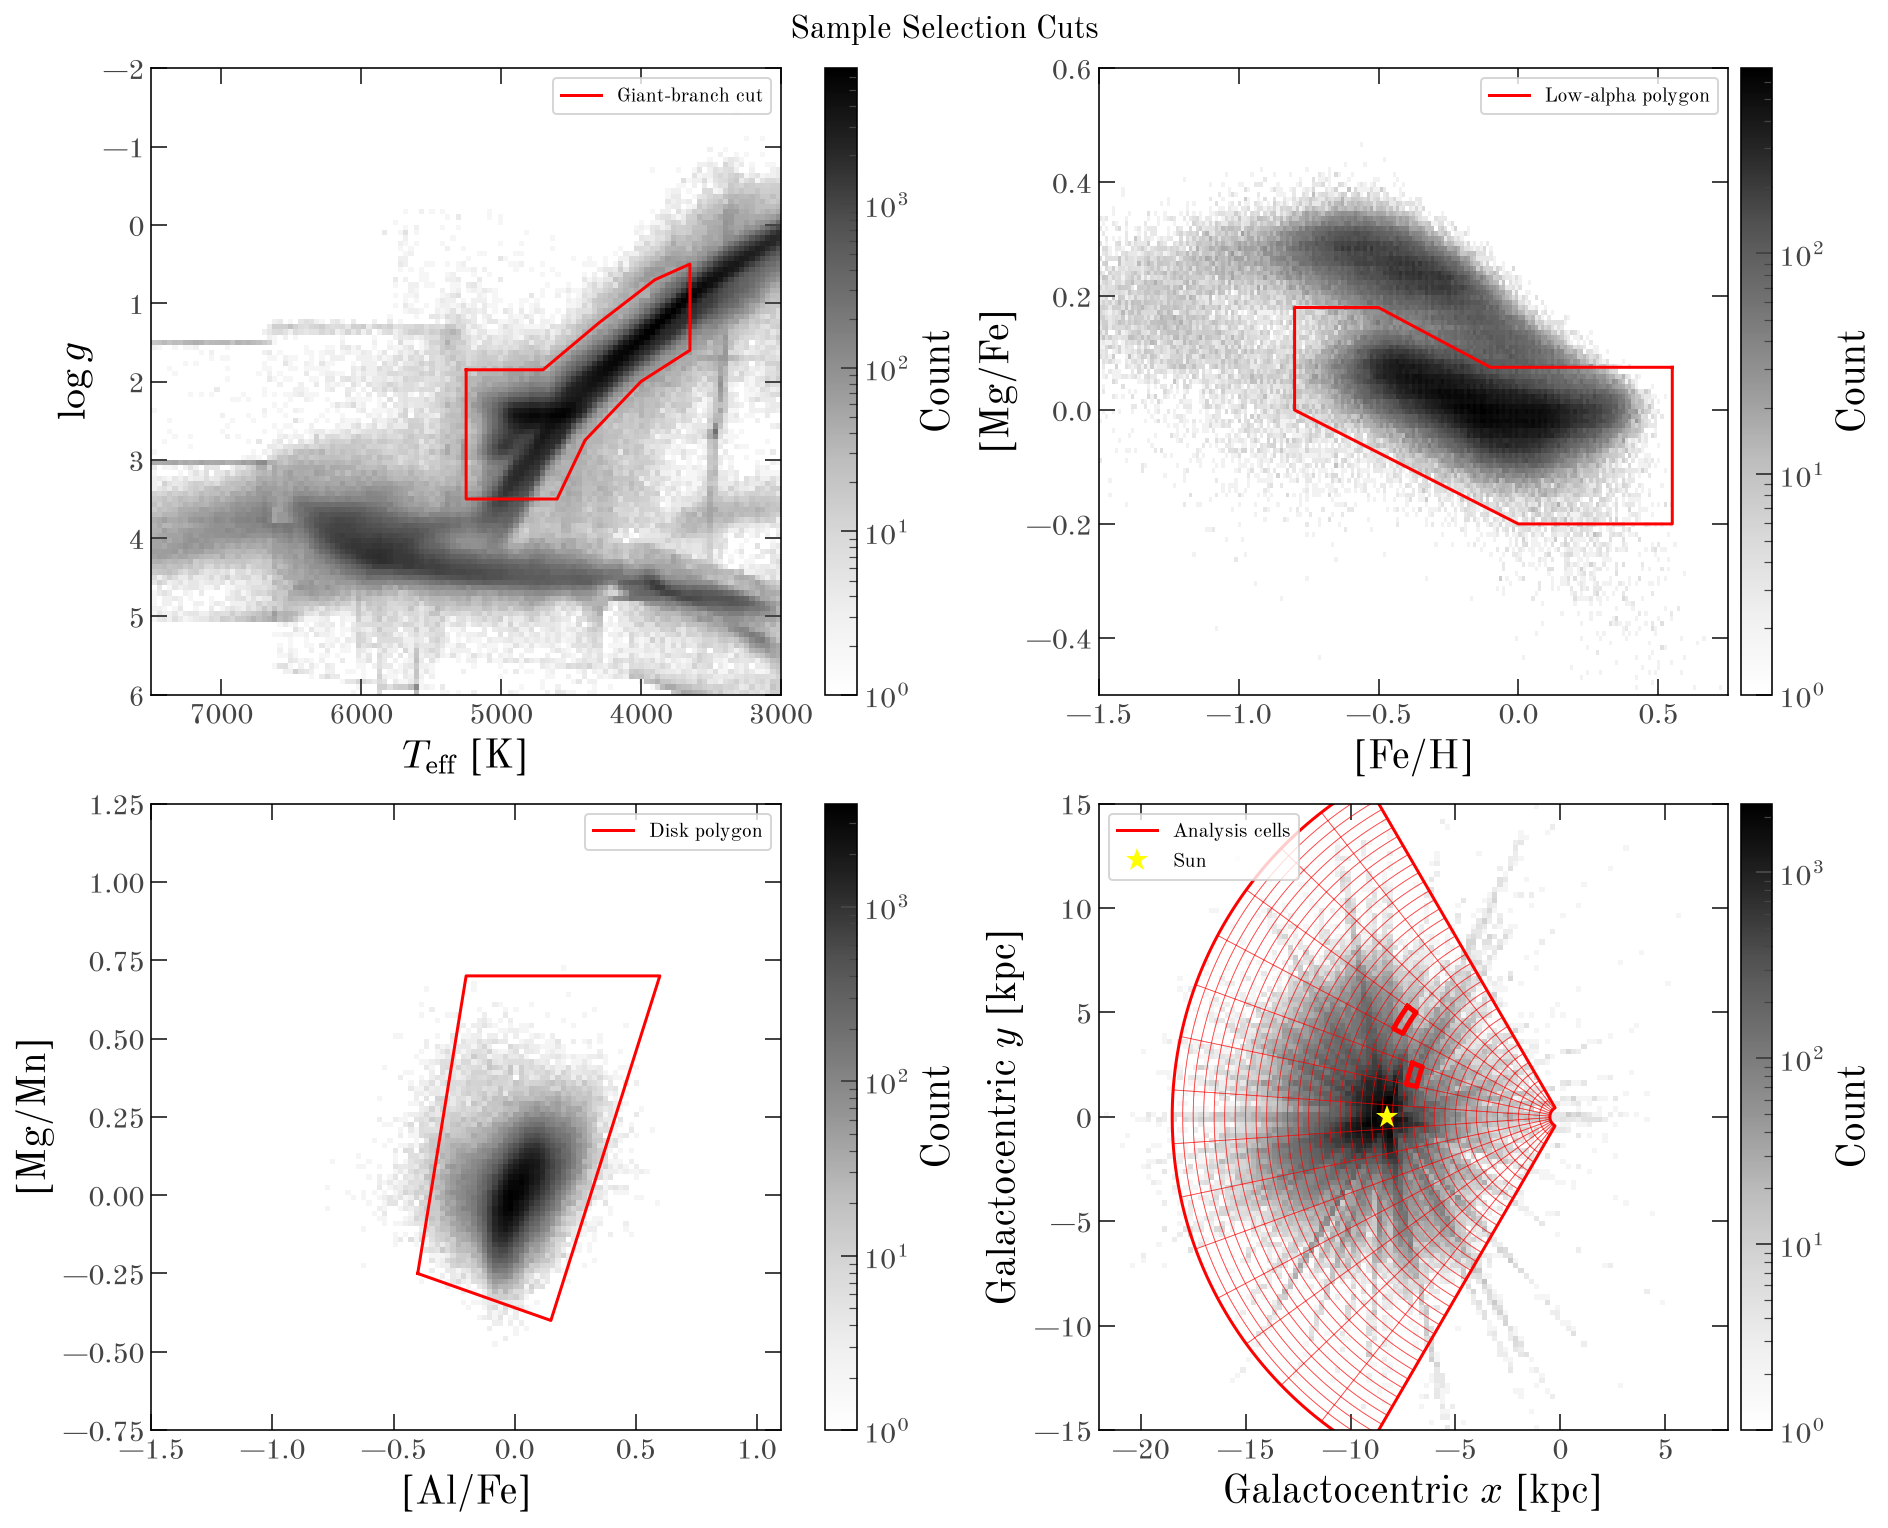

In [10]:
fig, axes = plot_cuts(masks, "Sample Selection Cuts")
# fig.savefig(FIG_DIR / "sample_selection_cuts.pdf", dpi=300, bbox_inches="tight")
# fig.savefig(FIG_DIR / "sample_selection_cuts.png", dpi=300, bbox_inches="tight")

panel (a): 802,853 stars pass the quality cuts except the giant branch


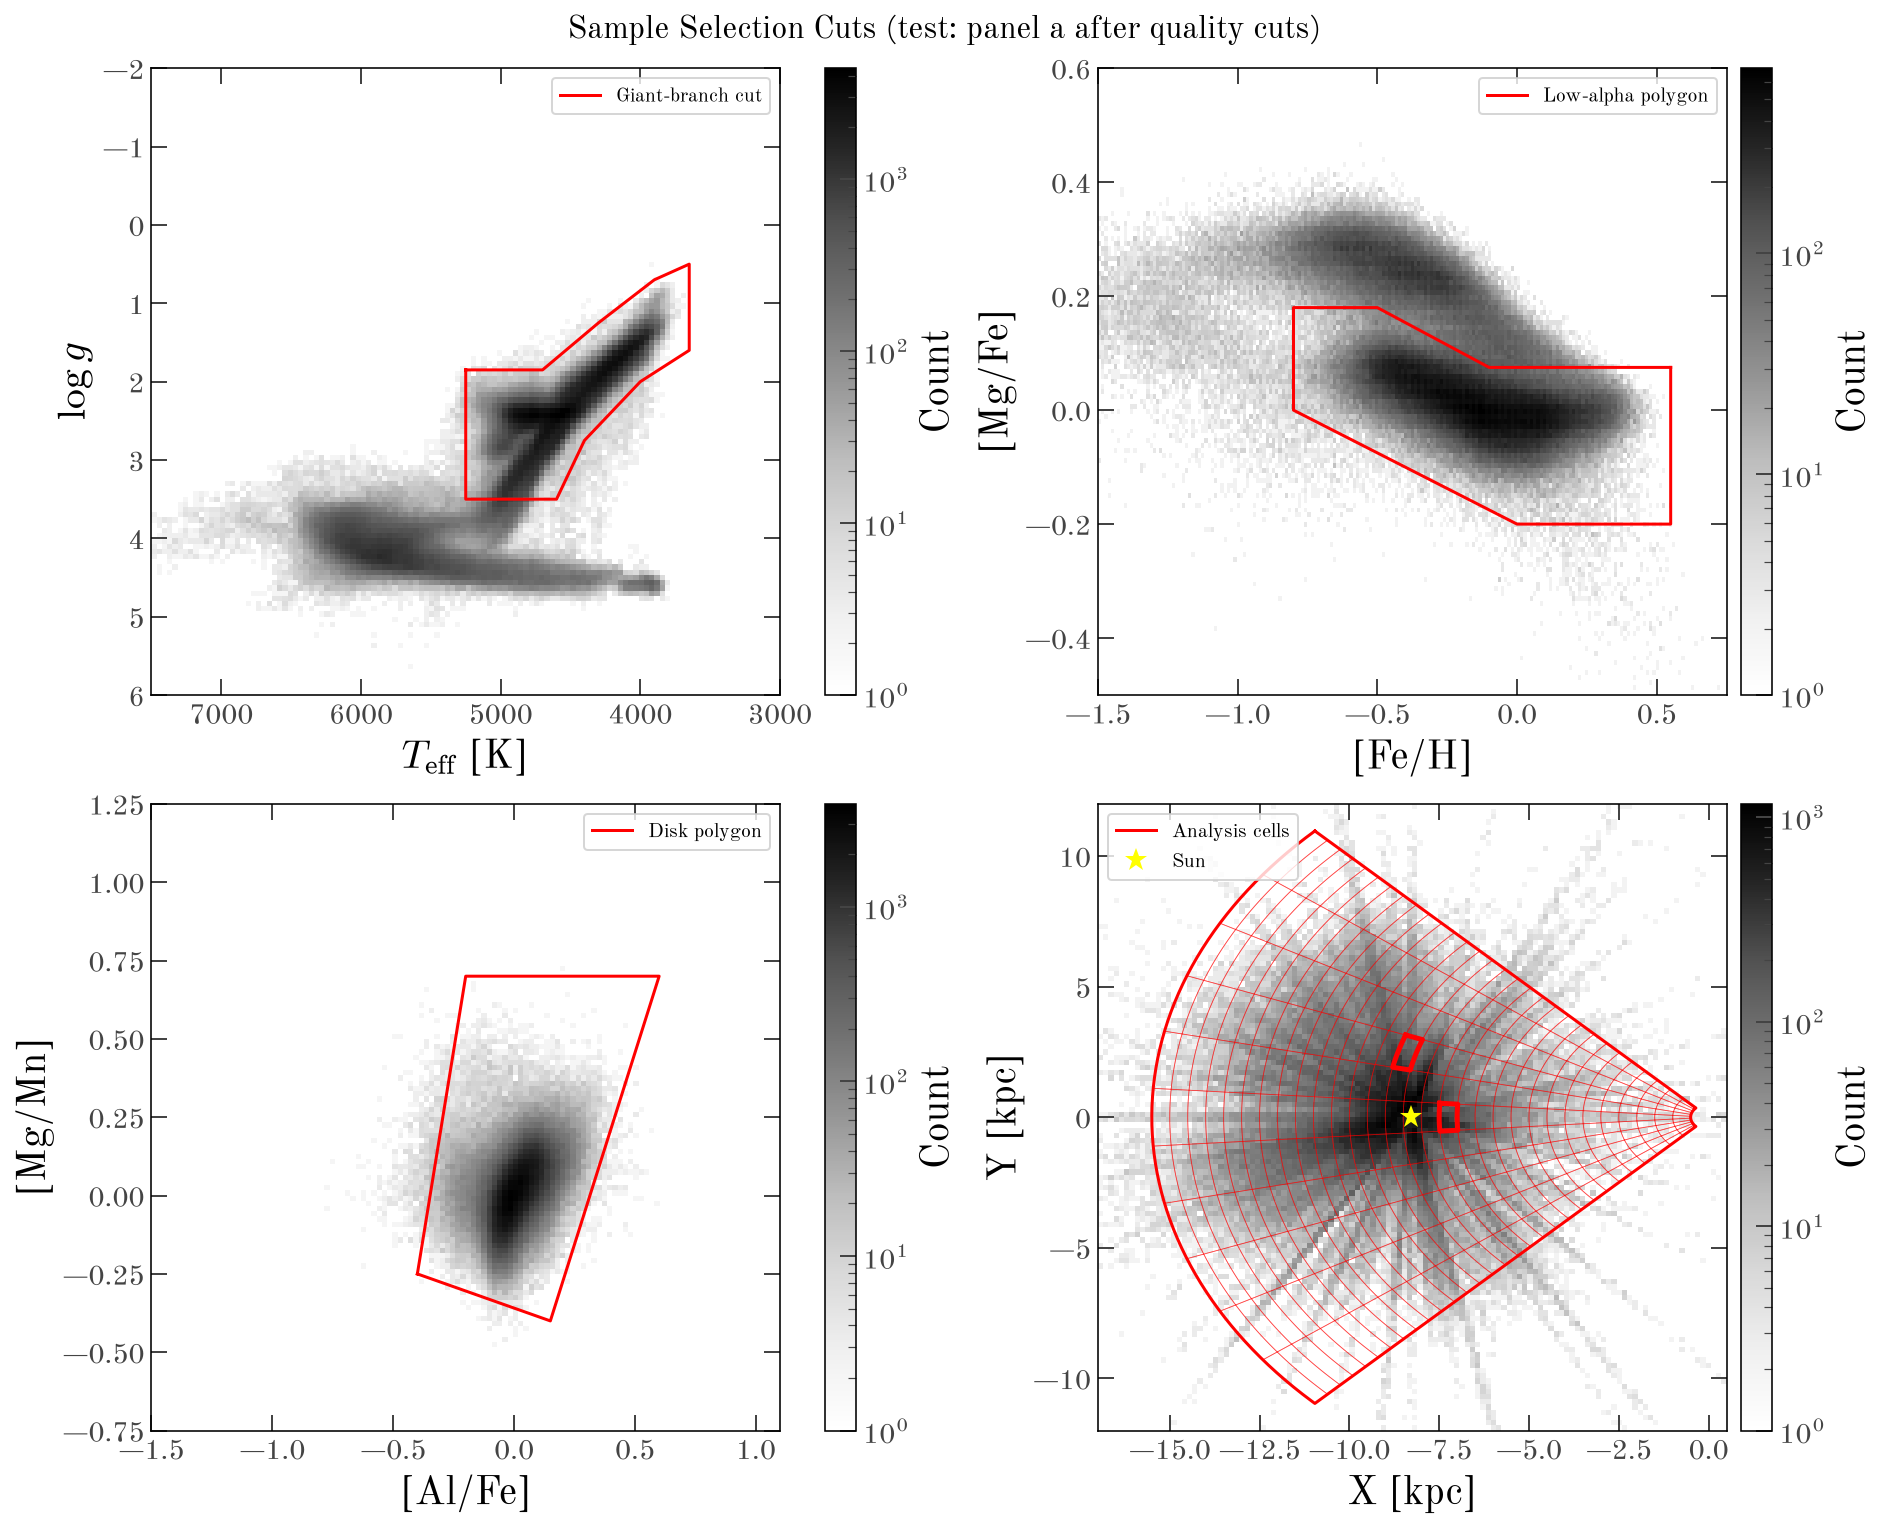

In [ ]:
quality_no_gb = passes(masks, before=LOW_ALPHA, skip=[GB])
print(
    f"panel (a): {quality_no_gb.sum():,} stars pass the quality cuts except the giant branch"
)
fig, axes = plot_cuts(
    masks,
    "Sample Selection Cuts (after quality cuts)",
    panel_a=quality_no_gb,
)

fig.savefig(FIG_DIR / "sample_selection_cuts.pdf", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "sample_selection_cuts.png", dpi=300, bbox_inches="tight")

## 6. Variants

### Looser ZGR quality cut: only flag bits 4 and 5 (values 16 and 32) must be clear (sample saved)

Compared with `zgr_quality_flags < 8`, this keeps stars with flag value 8 (poor SED fit) and any flag above 32.

In [ ]:
ZGR_BITMASK = 2**4 + 2**5  # 48

masks_zgr = selection_masks(t, zgr_bitmask=ZGR_BITMASK)
print(cut_log(masks_zgr).to_string(index=False))

fig, axes = plot_cuts(masks_zgr, "Sample Selection Cuts (test: zgr flag bits 4,5)")
plt.show()

save_sample(
    masks_zgr,
    DATA_DIR / "final_sample_zsun0_zgrbits45.fits",
    DATA_DIR / "final_sample_zsun0_zgrbits45_cut_log.csv",
    meta={
        "GCDIST": GALCEN_DISTANCE_KPC,
        "ZSUNPC": 0,
        "SNRMIN": SNR_MIN,
        "ZGRMASK": ZGR_BITMASK,  # zgr_quality_flags & ZGRMASK == 0
        "FEHMIN": FEH_MIN,
        "ASTRAFIL": ASTRA_FILE.name,  # parent Astra file
    },
);

### Extra cuts on log g and the red clump (figures only, nothing saved)

Each test adds one mask on top of the standard cuts and redraws the figure. Panel (a) still shows every star with finite Teff and logg.

In [ ]:
# where do the low-logg giants go? stars left after each cut, split by logg
logg = col_to_float_array(t, "logg")
print(f"{'step':48s} {'all':>10s} {'logg<1':>10s} {'1-2.8':>10s} {'>2.8':>10s}")
left = np.ones(len(t), bool)
for label, mask in masks.items():
    left &= mask
    print(
        f"{label:48s} {left.sum():10,d} {(left & (logg < 1)).sum():10,d} "
        f"{(left & (logg >= 1) & (logg < 2.8)).sum():10,d} {(left & (logg >= 2.8)).sum():10,d}"
    )

In [ ]:
LOGG_MIN, LOGG_MAX = 1.0, 2.8

for lo, title in [
    (None, rf"Sample Selection Cuts (test: $\log g < {LOGG_MAX}$)"),
    (LOGG_MIN, rf"Sample Selection Cuts (test: ${LOGG_MIN} < \log g < {LOGG_MAX}$)"),
]:
    extra = (logg < LOGG_MAX) if lo is None else (logg > lo) & (logg < LOGG_MAX)
    print(f"{title}: final sample {final.sum():,} -> {(final & extra).sum():,}")
    fig, axes = plot_cuts(masks, title, extra=extra)
    ax = axes[0, 0]
    ax.axhline(LOGG_MAX, color=RED, lw=1.5, ls="--", label=rf"$\log g = {LOGG_MAX}$")
    if lo is not None:
        ax.axhline(lo, color=RED, lw=1.5, ls=":", label=rf"$\log g = {lo}$")
    ax.legend(loc="upper right")
    plt.show()

In [ ]:
RC_TEFF = (4500, 5100)  # red clump box in Teff [K]
RC_LOGG = (2.2, 2.7)  # red clump box in logg
APPLY_LOGG_CUT = False  # also apply the LOGG_MIN < logg < LOGG_MAX cut from above

teff = col_to_float_array(t, "teff")
in_rc = (
    (teff > RC_TEFF[0])
    & (teff < RC_TEFF[1])
    & (logg > RC_LOGG[0])
    & (logg < RC_LOGG[1])
)
extra = ~in_rc
if APPLY_LOGG_CUT:
    extra &= (logg > LOGG_MIN) & (logg < LOGG_MAX)
print(f"red clump removed: final sample {final.sum():,} -> {(final & extra).sum():,}")

fig, axes = plot_cuts(
    masks, "Sample Selection Cuts (test: red clump removed)", extra=extra
)
ax = axes[0, 0]
ax.add_patch(
    Rectangle(
        (RC_TEFF[0], RC_LOGG[0]),
        RC_TEFF[1] - RC_TEFF[0],
        RC_LOGG[1] - RC_LOGG[0],
        fill=False,
        edgecolor=RED,
        lw=1.5,
        ls="--",
        label="Red clump (removed)",
    )
)
if APPLY_LOGG_CUT:
    ax.axhline(LOGG_MAX, color=RED, lw=1.5, ls=":")
    ax.axhline(
        LOGG_MIN,
        color=RED,
        lw=1.5,
        ls=":",
        label=rf"${LOGG_MIN} < \log g < {LOGG_MAX}$",
    )
ax.legend(loc="upper right")
plt.show()